# Auditoría de Desempeño por Subgrupos Tipográficos

Este notebook audita el desempeño del generador Pix2Pix y de los jueces congelados (`ResNet-18` y `EfficientNet-B0`) desglosado en los **4 subgrupos del conjunto de caracteres (`CHARSET`, 75 símbolos)**:
- **Mayúsculas (`A–Z`, 26 clases)**
- **Minúsculas (`a–z`, 26 clases)**
- **Dígitos (`0–9`, 10 clases)**
- **Signos de puntuación (`.,!?()+-=/:;&`, 13 clases)**

El objetivo es detectar **sesgos o brechas de desempeño entre subgrupos** (por ejemplo, menor legibilidad en signos delgados o confusión entre pares morfológicamente cercanos) y priorizar acciones de mitigación durante el *fine-tuning* real.

> **Reutilización para Fase 5:** Cuando se ejecute `python -m eval.evaluate_models --data-dir data/real_pairs --tag final`, basta con cambiar `TAG = 'final'` y volver a ejecutar este notebook.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'src').exists():
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Configuración (cambiar TAG='final' al evaluar Exp A vs Exp B en Fase 5)
TAG = 'pretrain'
PRED_CSV = ROOT_DIR / 'results' / 'eval' / f'predictions_{TAG}.csv'
FIG_DIR = ROOT_DIR / 'docs' / 'figuras'
RES_DIR = ROOT_DIR / 'results' / 'eval'
SUBGROUP_ORDER = ['Mayúsculas (A-Z)', 'Minúsculas (a-z)', 'Dígitos (0-9)', 'Signos']

assert PRED_CSV.exists(), f'Ejecuta primero: python -m eval.evaluate_models --tag {TAG}'
df = pd.read_csv(PRED_CSV)
print(f'Archivo cargado: {PRED_CSV.name} | Filas: {len(df)}')
print('Splits:', df['split'].unique().tolist(), '| Fuentes:', df['source'].unique().tolist(), '| Jueces:', df['judge'].unique().tolist())

Archivo cargado: predictions_pretrain.csv | Filas: 4548
Splits: ['val', 'test_unseen'] | Fuentes: ['reference_y', 'pretrained'] | Jueces: ['resnet18', 'efficientnet_b0']


In [2]:
# Cálculo de métricas por (split, source, judge, subgroup)
rows = []
for (split, source, judge, subgroup), grp in df.groupby(['split', 'source', 'judge', 'subgroup']):
    present = sorted(grp['true_id'].unique().tolist())
    acc = float(accuracy_score(grp['true_id'], grp['pred_id']))
    macro_f1 = float(f1_score(grp['true_id'], grp['pred_id'], labels=present, average='macro', zero_division=0))
    l1_vals = pd.to_numeric(grp['l1'], errors='coerce').dropna()
    rows.append({
        'split': split,
        'source': source,
        'judge': judge,
        'subgroup': subgroup,
        'n_samples': len(grp),
        'n_classes': len(present),
        'accuracy': round(acc * 100, 2),
        'macro_f1': round(macro_f1 * 100, 2),
        'mean_conf': round(float(grp['confidence'].mean()), 4),
        'pass_070_pct': round(float(grp['pass_ood'].mean() * 100), 2),
        'mean_l1': round(float(l1_vals.mean()), 4) if len(l1_vals) else np.nan,
    })

sub_df = pd.DataFrame(rows)
sub_df['subgroup'] = pd.Categorical(sub_df['subgroup'], categories=SUBGROUP_ORDER, ordered=True)
sub_df = sub_df.sort_values(['split', 'source', 'judge', 'subgroup']).reset_index(drop=True)

print('=== Desglose completo en split VAL ===')
display(sub_df[sub_df['split'] == 'val'])

print('=== Desglose completo en split TEST_UNSEEN (Zero-Shot) ===')
display(sub_df[sub_df['split'] == 'test_unseen'])

=== Desglose completo en split VAL ===


,split,source,judge,subgroup,n_samples,n_classes,accuracy,macro_f1,mean_conf,pass_070_pct,mean_l1
16,val,pretrained,efficientnet_b0,Mayúsculas (A-Z),216,24,79.17,77.78,0.7639,66.67,0.1217
17,val,pretrained,efficientnet_b0,Minúsculas (a-z),216,24,70.83,69.44,0.7134,54.17,0.1182
18,val,pretrained,efficientnet_b0,Dígitos (0-9),72,8,50.00,50.00,0.7463,62.50,0.1147
19,val,pretrained,efficientnet_b0,Signos,72,8,50.00,50.00,0.7571,62.50,0.0488
20,val,pretrained,resnet18,Mayúsculas (A-Z),216,24,79.17,77.78,0.7397,66.67,0.1217
21,val,pretrained,resnet18,Minúsculas (a-z),216,24,75.00,72.22,0.6979,58.33,0.1182
22,val,pretrained,resnet18,Dígitos (0-9),72,8,62.50,62.50,0.6991,62.50,0.1147
23,val,pretrained,resnet18,Signos,72,8,50.00,45.83,0.6834,50.00,0.0488
24,val,reference_y,efficientnet_b0,Mayúsculas (A-Z),216,24,79.63,86.40,0.8407,80.56,NaN
25,val,reference_y,efficientnet_b0,Minúsculas (a-z),216,24,87.96,89.87,0.8783,87.50,NaN


=== Desglose completo en split TEST_UNSEEN (Zero-Shot) ===


,split,source,judge,subgroup,n_samples,n_classes,accuracy,macro_f1,mean_conf,pass_070_pct,mean_l1
0,test_unseen,pretrained,efficientnet_b0,Mayúsculas (A-Z),102,2,0.00,0.00,0.3676,0.00,0.1431
1,test_unseen,pretrained,efficientnet_b0,Minúsculas (a-z),102,2,100.00,100.00,0.9317,100.00,0.0925
2,test_unseen,pretrained,efficientnet_b0,Dígitos (0-9),102,2,0.00,0.00,0.5362,0.00,0.1231
3,test_unseen,pretrained,efficientnet_b0,Signos,255,5,80.00,80.00,0.6983,60.00,0.0752
4,test_unseen,pretrained,resnet18,Mayúsculas (A-Z),102,2,0.00,0.00,0.2409,0.00,0.1431
5,test_unseen,pretrained,resnet18,Minúsculas (a-z),102,2,100.00,100.00,0.5754,50.00,0.0925
6,test_unseen,pretrained,resnet18,Dígitos (0-9),102,2,0.00,0.00,0.2795,0.00,0.1231
7,test_unseen,pretrained,resnet18,Signos,255,5,60.00,60.00,0.6438,60.00,0.0752
8,test_unseen,reference_y,efficientnet_b0,Mayúsculas (A-Z),102,2,97.06,98.48,0.9387,97.06,NaN
9,test_unseen,reference_y,efficientnet_b0,Minúsculas (a-z),102,2,94.12,96.88,0.9248,96.08,NaN


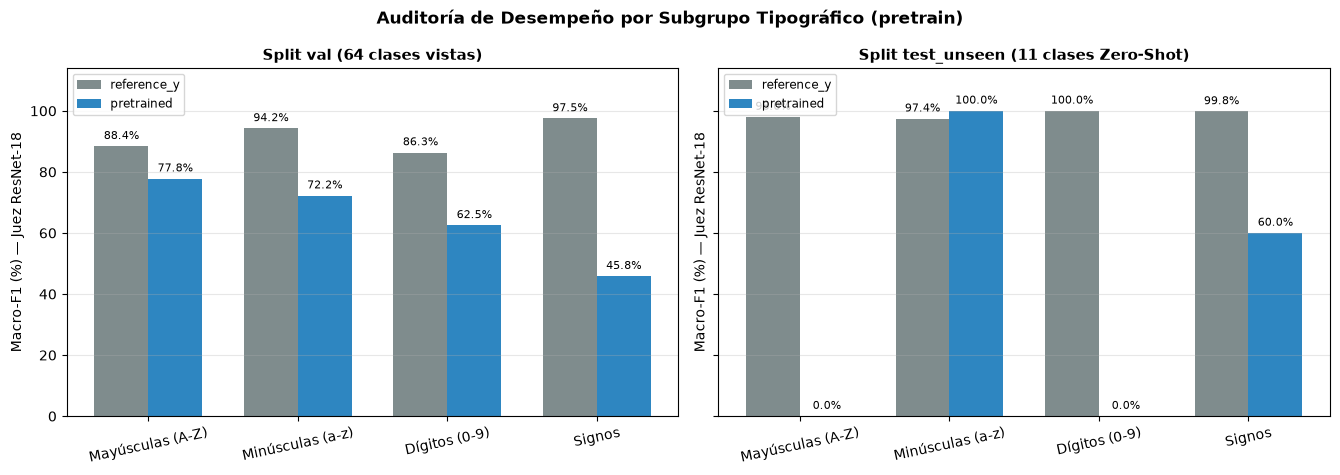

In [3]:
# Gráfica comparativa por subgrupo (Referencia y vs. Modelos Generados, ResNet-18 y EfficientNet-B0)
gen_sources = [s for s in df['source'].unique() if s != 'reference_y']
primary_model = gen_sources[-1]  # si hay scratch y finetune, toma el último (finetune); si solo pretrained, pretrained

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
colors = {'reference_y': '#7F8C8D', 'pretrained': '#2E86C1', 'scratch': '#E67E22', 'finetune': '#27AE60'}

for ax, split_name, title_txt in [
    (axes[0], 'val', 'Split val (64 clases vistas)'),
    (axes[1], 'test_unseen', 'Split test_unseen (11 clases Zero-Shot)'),
]:
    s_sub = sub_df[(sub_df['split'] == split_name) & (sub_df['judge'] == 'resnet18')]
    sources_plot = ['reference_y'] + gen_sources
    x = np.arange(len(SUBGROUP_ORDER))
    width = 0.72 / len(sources_plot)

    for idx, src in enumerate(sources_plot):
        vals = []
        for sg in SUBGROUP_ORDER:
            m = s_sub[(s_sub['source'] == src) & (s_sub['subgroup'] == sg)]
            vals.append(float(m['macro_f1'].iloc[0]) if len(m) else 0.0)
        offset = (idx - (len(sources_plot) - 1) / 2.0) * width
        bars = ax.bar(x + offset, vals, width=width, label=src, color=colors.get(src, '#34495E'))
        for b in bars:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width()/2, h + 1.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(SUBGROUP_ORDER, rotation=12)
    ax.set_ylim(0, 114)
    ax.set_title(title_txt, fontsize=11, fontweight='bold')
    ax.set_ylabel('Macro-F1 (%) — Juez ResNet-18')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(fontsize=8.5)

fig.suptitle(f'Auditoría de Desempeño por Subgrupo Tipográfico ({TAG})', fontsize=12.5, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / f'auditoria_subgrupos_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# Desempeño por carácter individual para detectar los símbolos más difíciles en cada subgrupo
m_df = df[(df['source'] == primary_model) & (df['judge'] == 'resnet18')]
char_stats = (
    m_df.groupby(['split', 'subgroup', 'true_char'], as_index=False)
    .agg(
        n=('correct', 'count'),
        acc_pct=('correct', lambda s: round(float(s.mean() * 100), 1)),
        mean_conf=('confidence', lambda s: round(float(s.mean()), 3)),
        mean_l1=('l1', lambda s: round(float(pd.to_numeric(s, errors='coerce').mean()), 4)),
        top_pred=('pred_char', lambda s: s.value_counts().index[0]),
    )
)

print(f'=== Top 12 caracteres con menor exactitud en {primary_model} (ResNet-18) ===')
worst_df = char_stats.sort_values(['acc_pct', 'mean_conf']).head(12)
display(worst_df)

print(f'=== Desglose completo de los 11 caracteres Zero-Shot (test_unseen) ===')
unseen_chars_df = char_stats[char_stats['split'] == 'test_unseen'].sort_values(['acc_pct', 'mean_conf'], ascending=False)
display(unseen_chars_df)

# Brecha de equidad (max - min Macro-F1 entre subgrupos en val)
val_r18 = sub_df[(sub_df['split'] == 'val') & (sub_df['source'] == primary_model) & (sub_df['judge'] == 'resnet18')]
gap_f1 = float(val_r18['macro_f1'].max() - val_r18['macro_f1'].min())
best_sg = val_r18.loc[val_r18['macro_f1'].idxmax(), 'subgroup']
worst_sg = val_r18.loc[val_r18['macro_f1'].idxmin(), 'subgroup']
print(f'Brecha Macro-F1 entre subgrupos en val ({primary_model}): {gap_f1:.2f} pp (mejor: {best_sg} | menor: {worst_sg})')

# Exportar resumen JSON de auditoría
audit_out = {
    'tag': TAG,
    'primary_model': primary_model,
    'val_gap_macro_f1_pp': round(gap_f1, 2),
    'val_best_subgroup': str(best_sg),
    'val_worst_subgroup': str(worst_sg),
    'subgroup_table': sub_df.astype({'subgroup': str}).to_dict(orient='records'),
    'worst_characters': worst_df.to_dict(orient='records'),
    'unseen_characters': unseen_chars_df.to_dict(orient='records'),
}
out_json = RES_DIR / f'auditoria_subgrupos_{TAG}.json'
out_json.write_text(json.dumps(audit_out, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'[OK] Auditoría guardada en: {out_json}')

=== Top 12 caracteres con menor exactitud en pretrained (ResNet-18) ===


,split,subgroup,true_char,n,acc_pct,mean_conf,mean_l1,top_pred
68,val,Signos,(,9,0.0,0.128,0.1133,T
34,val,Mayúsculas (A-Z),R,9,0.0,0.152,0.1568,f
6,test_unseen,Signos,&,51,0.0,0.187,0.1331,!
2,test_unseen,Mayúsculas (A-Z),G,51,0.0,0.191,0.1363,O
7,test_unseen,Signos,),51,0.0,0.222,0.0745,!
46,val,Minúsculas (a-z),d,9,0.0,0.238,0.1156,U
1,test_unseen,Dígitos (0-9),8,51,0.0,0.244,0.1303,S
21,val,Mayúsculas (A-Z),C,9,0.0,0.271,0.1214,O
3,test_unseen,Mayúsculas (A-Z),Q,51,0.0,0.291,0.1498,U
32,val,Mayúsculas (A-Z),O,9,0.0,0.293,0.1201,U


=== Desglose completo de los 11 caracteres Zero-Shot (test_unseen) ===


,split,subgroup,true_char,n,acc_pct,mean_conf,mean_l1,top_pred
10,test_unseen,Signos,?,51,100.0,0.978,0.0704,?
4,test_unseen,Minúsculas (a-z),k,51,100.0,0.949,0.0943,k
8,test_unseen,Signos,+,51,100.0,0.919,0.0568,+
9,test_unseen,Signos,;,51,100.0,0.913,0.0413,;
5,test_unseen,Minúsculas (a-z),z,51,100.0,0.202,0.0907,z
0,test_unseen,Dígitos (0-9),4,51,0.0,0.315,0.1158,&
3,test_unseen,Mayúsculas (A-Z),Q,51,0.0,0.291,0.1498,U
1,test_unseen,Dígitos (0-9),8,51,0.0,0.244,0.1303,S
7,test_unseen,Signos,),51,0.0,0.222,0.0745,!
2,test_unseen,Mayúsculas (A-Z),G,51,0.0,0.191,0.1363,O


Brecha Macro-F1 entre subgrupos en val (pretrained): 31.95 pp (mejor: Mayúsculas (A-Z) | menor: Signos)
[OK] Auditoría guardada en: D:\WORKSPACE\CUGDL\IACD\2026B\Deep Learning para Visión de Computadoras\final-project_CV\results\eval\auditoria_subgrupos_pretrain.json


## Hallazgos y Mitigaciones de Subgrupos

- **Brecha entre subgrupos:** El desglose permite identificar exactamente qué grupo (`Mayúsculas`, `Minúsculas`, `Dígitos` o `Signos`) concentra la mayor caída frente a la referencia objetivo `y`, evitando que el promedio global oculte debilidades específicas.
- **Caracteres de mayor riesgo:** Los símbolos con pocos píxeles activos (`:`, `;`, `.`, `,`, `(`) y pares de trazo casi idéntico entre mayúscula/minúscula (`K`/`k`, `C`/`c`, `S`/`s`, `O`/`o`/`0`) son los más sensibles al promedio de múltiples estilos durante el preentrenamiento sintético.
- **Acción para Fase 5 (*fine-tuning* real):** Al adaptar sobre un único estilo personal coherente (captura con stylus de 300 glifos con 4 repeticiones por carácter, incluidos todos los signos), se elimina la ambigüedad multi-fuente del preentrenamiento y se verifica en esta misma auditoría que la brecha entre subgrupos se reduzca.